In [1]:
import gudhi
import modules as mod
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan

- example from ali (make it into a "finite" rectangle module") 
- make rectangles open to the right, top in code 
- compute matching distance for each pair of critical points

### To do : add visualization of modules
https://www.geeksforgeeks.org/matplotlib-patches-rectangle-in-python/ 

In [2]:
rect_m1 = mod.Rectangle((0,-1),(7,6),1)
rect_m2 = mod.Rectangle((0,3),(7,10),1)
M = mod.RectangleModule([rect_m1,rect_m2])
rect_n1 = mod.Rectangle((0,-1),(7,10),1)
rect_n2 = mod.Rectangle((0,3),(7,6),1)
N= mod.RectangleModule([rect_n1,rect_n2])

In [3]:
L = mod.Line((1,1),(0,0))
L_low = mod.Line((1,1),(1/2,-1/2))
L_up = mod.line_through_2points((0,3),(7,10))
L_up.b

(-1.5, 1.5)

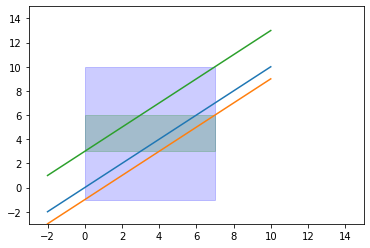

In [4]:
fig = plt.figure()
ax = fig.add_subplot(111)

a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
 
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

x = np.linspace(-2, 10, 1000)
plt.plot(x, x + 0, linestyle='solid') ##L 
plt.plot(x, x -1, linestyle='solid') 
plt.plot(x, x + 3, linestyle='solid') 



ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
  
plt.show()

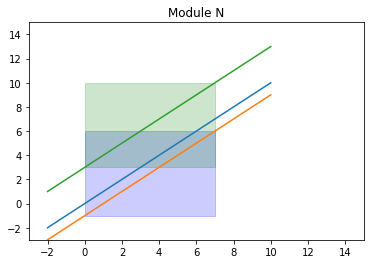

In [5]:
fig = plt.figure()
ax = fig.add_subplot(111)
## rectangles 
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)
plt.plot(x, x + 0, linestyle='solid') ##L 
plt.plot(x, x -1, linestyle='solid') 
plt.plot(x, x + 3, linestyle='solid') 

ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])

plt.title('Module N')  
plt.show()

Text(0.5, 1.0, 'Module N')

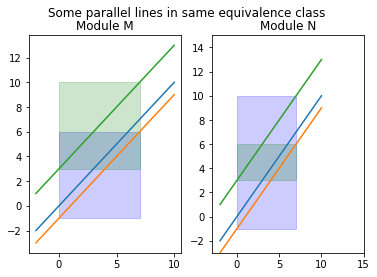

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Some parallel lines in same equivalence class  ')
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

x = np.linspace(-2, 10, 1000)
ax1.plot(x, x + 0, linestyle='solid') ##L 
ax1.plot(x, x -1, linestyle='solid')  ##L_low
ax1.plot(x, x + 3, linestyle='solid') ##L_up



ax1.add_patch(rect1)
ax1.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax1.set_title('Module M')

###
a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)
ax2.plot(x, x + 0, linestyle='solid') ##L 
ax2.plot(x, x -1, linestyle='solid') 
ax2.plot(x, x + 3, linestyle='solid') 

ax2.add_patch(rect1)
ax2.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax2.set_title('Module N')

In [7]:
[inter_m1, param_m1] = rect_m1.find_intersection(L_low)
print(inter_m1)
[inter_m2, param_m2] = rect_m2.find_intersection(L_low)
print(inter_m2)
dgmM = M.compute_barcode(L_low)
print(dgmM)

[(0.0, -1), (7.0, 6)]
[(4.0, 3), (7, 6.0)]
[[-0.5, 6.5], [3.5, 6.5]]


In [8]:
## Family of lines in same equivalence class 
n = 100 ## number of points in interval 
t = 2/n 
Lines = []
wbd=[]
x=[]
for i in range(n+1):
    b= i*t
    x.append(-1.5+b)
    #print(b)
    line = mod.Line((1,1),(-1.5+b,1.5-b))
    print(line.b)
    #print(line.m)
    #print(line.b)
    Lines.append(line)
    d = mod.compute_weighted_bottleneck(M,N,line)
    wbd.append(d)
    print(d)
    #print('------')
    

(-1.5, 1.5)
1.791683820432063e-308
(-1.48, 1.48)
0.04000000000000003
(-1.46, 1.46)
0.08000000000000007
(-1.44, 1.44)
0.12000000000000009
(-1.42, 1.42)
0.16000000000000014
(-1.4, 1.4)
0.20000000000000018
(-1.38, 1.38)
0.2400000000000002
(-1.3599999999999999, 1.3599999999999999)
0.28000000000000025
(-1.34, 1.34)
0.31999999999999984
(-1.32, 1.32)
0.3599999999999999
(-1.3, 1.3)
0.39999999999999986
(-1.28, 1.28)
0.43999999999999995
(-1.26, 1.26)
0.48
(-1.24, 1.24)
0.52
(-1.22, 1.22)
0.5599999999999999
(-1.2, 1.2)
0.6
(-1.18, 1.18)
0.64
(-1.16, 1.16)
0.6800000000000002
(-1.1400000000000001, 1.1400000000000001)
0.7199999999999998
(-1.12, 1.12)
0.7599999999999998
(-1.1, 1.1)
0.7999999999999998
(-1.08, 1.08)
0.8399999999999999
(-1.06, 1.06)
0.8799999999999998
(-1.04, 1.04)
0.9199999999999998
(-1.02, 1.02)
0.96
(-1.0, 1.0)
1.0
(-0.98, 0.98)
1.0399999999999998
(-0.96, 0.96)
1.0799999999999998
(-0.94, 0.94)
1.1199999999999999
(-0.92, 0.92)
1.16
(-0.9, 0.9)
1.2000000000000002
(-0.88, 0.88)
1.240000

In [9]:
mod.compute_weighted_bottleneck(M,N,L)

1.0

Text(0, 0.5, 'weighted bottleneck distance')

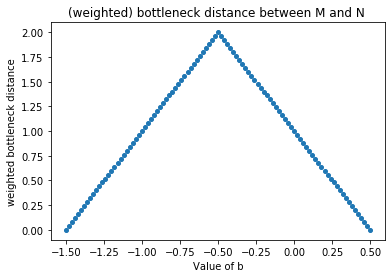

In [10]:
fig, ax = plt.subplots()
plt.plot(x, wbd, 'o',markersize = 4)
plt.title('(weighted) bottleneck distance between M and N ')
plt.xlabel('Value of b')
plt.ylabel('weighted bottleneck distance')

### computing bottleneck distance for all parallel lines of direction (1,1)

In [11]:
##line through 
L_mid_top = mod.Line((1,1), (0,6))
L_top = mod.Line((1,1),(0,10))
L_mid_low = mod.Line((1,1),(7,3))
L_low = mod.Line((1,1),(7,0))

In [12]:
print(L_mid_top.b)
print(L_top.b)
print(L_mid_low.b)
print(L_low.b)

(-3.0, 3.0)
(-5.0, 5.0)
(2.0, -2.0)
(3.5, -3.5)


In [13]:
## Family of lines in different equivalence class, all parallel to the direction (1,1)
n = 400 ## number of points ininterval 
t = 8.5/n 
Lines = []
wbd=[]
x=[]
for i in range(n+1):
    b= i*t
    x.append(-5+b)
    #print(b)
    line = mod.Line((1,1),(-5+b,5-b))
    #print(line.b)
    #print(line.m)
    #print(line.b)
    Lines.append(line)
    d = mod.compute_weighted_bottleneck(M,N,line)
    wbd.append(d)
    #print(d)
    #print('------')

Text(0, 0.5, 'weighted bottleneck distance')

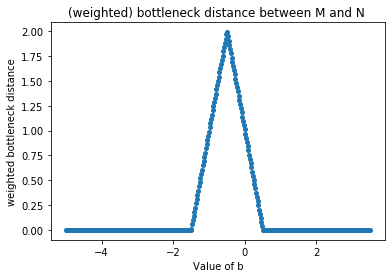

In [14]:
fig, ax = plt.subplots()
plt.plot(x, wbd, 'o',markersize = 4)
plt.title('(weighted) bottleneck distance between M and N ')
plt.xlabel('Value of b')
plt.ylabel('weighted bottleneck distance')

#### plotting the line with maximum bottleneck distance

Text(0.5, 1.0, 'Module N')

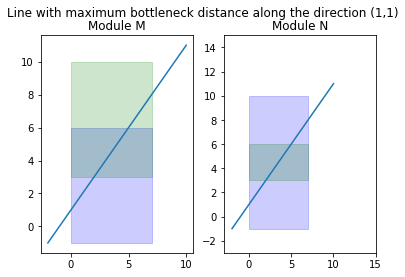

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2)
fig.suptitle('Line with maximum bottleneck distance along the direction (1,1)')
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

x = np.linspace(-2, 10, 1000)
ax1.plot(x, x +1, linestyle='solid')  ##L_low



ax1.add_patch(rect1)
ax1.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax1.set_title('Module M')

###
a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)
ax2.plot(x, x +1, linestyle='solid') 


ax2.add_patch(rect1)
ax2.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax2.set_title('Module N')

In [16]:
L = mod.Line((1,1), (-0.5,0.5))

Text(0.5, 1.0, 'Module N')

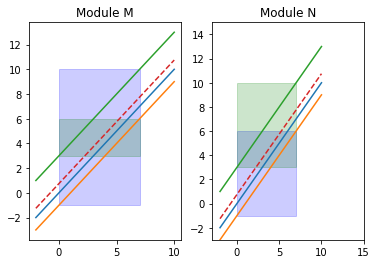

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2)
#fig.suptitle('Horizontally stacked subplots')
a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
 
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

x = np.linspace(-2, 10, 1000)
ax1.plot(x, x + 0, linestyle='solid') ##L 
ax1.plot(x, x -1, linestyle='solid') 
ax1.plot(x, x + 3, linestyle='solid') 
ax1.plot(x, x + 0.75, linestyle='dashed') ## check this corresponds to change in distance 
#ax1.plot(x, x + 0.25, linestyle='dashed')
ax1.add_patch(rect1)
ax1.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax1.set_title('Module M')

###
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)
ax2.plot(x, x + 0, linestyle='solid') ##L 
ax2.plot(x, x -1, linestyle='solid') 
ax2.plot(x, x + 3, linestyle='solid') 
ax2.plot(x, x + 0.75, linestyle='dashed') 

ax2.add_patch(rect1)
ax2.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])
ax2.set_title('Module N')

####  check line through bottom left and top right

##  2D plot with coordinates (b,theta) 

In [18]:
Crit_M = M.find_critical_pts() ## M and N have the same critical values
#print(Crit_M)
Lines = []
D = []
k = 0
Crit = []
for i in range(len(Crit_M)-1):
    p = Crit_M[i]
    for j in range(i+1,len(Crit_M)):
        q = Crit_M[j] 
        line = mod.line_through_2points(Crit_M[i], Crit_M[j])
        if line.positive: 
            d = mod.compute_weighted_bottleneck(M,N,line)
            Lines.append(line)
            Crit.append([Crit_M[i], Crit_M[j]])
            D.append(d)
print(D)

[1.161790309551409e-308, 1.807872510037103e-308, 8.220666940805944e-309, 1.134364624818219e-308, 2.5454545454545454, 1.791683820432063e-308]


In [19]:
Line = Lines[4]
b= Line.b[0]
theta = atan(Line.m[1]/Line.m[0])
print(theta)
print(b)
print(Line.m)

1.0040671092713902
0.3888888888888889
(0.6363636363636364, 1.0)


In [20]:
Theta = np.linspace(0,pi/2,100)[1:-1]
B = np.linspace(-5,5,100)
D= np.zeros((len(Theta), len(B)))
T = []
BB= []
Dist = []
for t in range(len(Theta)): 
    for n in range(len(B)): 
        s = sin(Theta[t])
        c = cos(Theta[t])
        maxm = max(s,c)
        line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
        d = mod.compute_weighted_bottleneck(M,N,line)
        D[t,n] = d
        T.append(Theta[t])
        BB.append(B[n])
        Dist.append(d)
print(max(Dist))     

2.5087216608069296


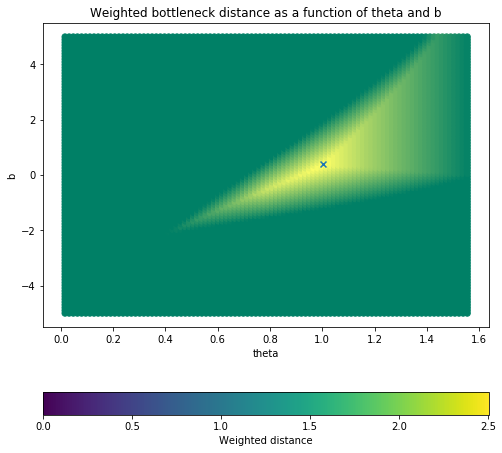

In [21]:
plt.figure(figsize=(8,8))
plt.scatter(T, BB, c= Dist, cmap = "summer")
plt.scatter(theta, b, marker = 'x')

#ratio = [1, 0.53, 2, 0.76, 0.5, 2.125, 0.561.28, 1.09, 1.02]
  
# scatterplot
#plt.scatter(x=purchaseCount, y=likes, c=ratio, cmap="summer")
plt.xlabel('theta')
plt.ylabel('b')
plt.title("Weighted bottleneck distance as a function of theta and b")
plt.colorbar(label="Weighted distance", orientation="horizontal")
plt.clim(0,max(Dist))
plt.show()

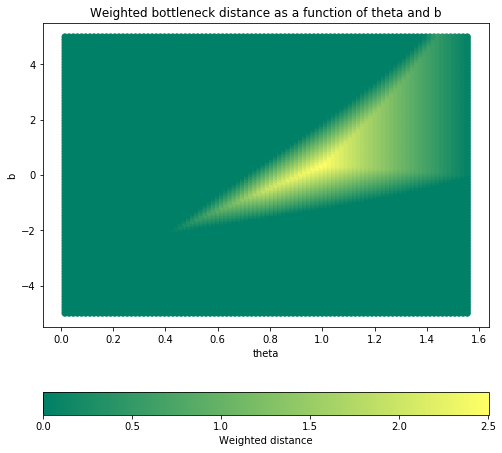

In [22]:
plt.figure(figsize=(8,8))
plt.scatter(T, BB, c= Dist, cmap = "summer")
#plt.scatter(theta, b, marker = 'x')

#ratio = [1, 0.53, 2, 0.76, 0.5, 2.125, 0.561.28, 1.09, 1.02]
  
# scatterplot
#plt.scatter(x=purchaseCount, y=likes, c=ratio, cmap="summer")
plt.xlabel('theta')
plt.ylabel('b')
plt.title("Weighted bottleneck distance as a function of theta and b")
plt.colorbar(label="Weighted distance", orientation="horizontal")
plt.clim(0,max(Dist))
plt.show()

## brute force suggestion: 
- all possible crosses corrresponding to line through two critical values (+coordidnates of critical values)
- create random examples to check the conjecture (do we get counter example or trust our intuition even though this is not mathematics) 
- infinite rectangles? 


### Some definitions: 
- rectanlge modules: generator bottom left and relation top right
- open to top and right = free module ==> matching distance is achieved at lines through a critical value and direction (1,1) (proved by Ali) 


finding the tesselation is equivalent to the algorithm 